In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

orders = pd.read_parquet("../data/processed/orders.parquet")
returns = pd.read_parquet("../data/processed/returns.parquet")
returns = returns.dropna(subset=["CustomerID"]).copy()
returns["CustomerID"] = returns["CustomerID"].astype(int)

print(orders.shape, returns.shape)
print(orders["InvoiceDate"].min(), orders["InvoiceDate"].max())

(36597, 7) (18744, 8)
2009-12-01 07:45:00 2011-12-09 12:50:00


In [5]:
def avg_gap(s):
    d = s.sort_values().diff().dt.days.dropna()
    return d.mean() if len(d) else np.nan

def build_dataset(cutoff, horizon=90, active_window=180):
    cutoff = pd.Timestamp(cutoff)
    end = cutoff + pd.Timedelta(days=horizon)

    past = orders[orders["InvoiceDate"] < cutoff]
    future = orders[(orders["InvoiceDate"] >= cutoff) & (orders["InvoiceDate"] < end)]

    last_order = past.groupby("CustomerID")["InvoiceDate"].max()
    active_ids = last_order[last_order >= cutoff - pd.Timedelta(days=active_window)].index
    past = past[past["CustomerID"].isin(active_ids)]

    g = past.groupby("CustomerID")
    X = pd.DataFrame({
        "recency": (cutoff - g["InvoiceDate"].max()).dt.days,
        "tenure": (cutoff - g["InvoiceDate"].min()).dt.days,
        "frequency": g["Invoice"].nunique(),
        "monetary": g["Revenue"].sum(),
        "avg_order_value": g["Revenue"].mean(),
        "avg_items": g["Items"].mean(),
        "avg_lines": g["Lines"].mean(),
        "is_uk": (g["Country"].first() == "United Kingdom").astype(int),
    })
    X["avg_gap_days"] = g["InvoiceDate"].apply(avg_gap)

    for days in (30, 90):
        recent = past[past["InvoiceDate"] >= cutoff - pd.Timedelta(days=days)]
        X[f"orders_last_{days}d"] = recent.groupby("CustomerID")["Invoice"].nunique()
        X[f"revenue_last_{days}d"] = recent.groupby("CustomerID")["Revenue"].sum()

    ret = returns[returns["InvoiceDate"] < cutoff].groupby("CustomerID").size()
    X["returns_cnt"] = ret

    fill0 = ["orders_last_30d", "revenue_last_30d", "orders_last_90d", "revenue_last_90d", "returns_cnt"]
    X[fill0] = X[fill0].fillna(0)

    X["churn"] = (~X.index.isin(future["CustomerID"].unique())).astype(int)
    return X

In [6]:
train_df = build_dataset("2011-03-10")
test_df = build_dataset("2011-09-10")

print("train:", train_df.shape, "| доля оттока:", round(train_df["churn"].mean(), 3))
print("test: ", test_df.shape, "| доля оттока:", round(test_df["churn"].mean(), 3))
train_df.head()

train: (3335, 15) | доля оттока: 0.578
test:  (2783, 15) | доля оттока: 0.382


,recency,tenure,frequency,monetary,avg_order_value,avg_items,avg_lines,is_uk,avg_gap_days,orders_last_30d,revenue_last_30d,orders_last_90d,revenue_last_90d,returns_cnt,churn
CustomerID,,,,,,,,,,,,,,,
12347,42,129,3,1798.71,599.57,381.0,33.333333,0,43.0,0.0,0.0,1.0,475.39,0.0,0
12348,43,163,3,1061.40,353.80,740.0,12.000000,0,59.5,0.0,0.0,2.0,840.24,0.0,0
12349,132,314,2,2221.14,1110.57,495.5,50.000000,0,181.0,0.0,0.0,0.0,0.00,5.0,1
12350,35,35,1,294.40,294.40,196.0,16.000000,0,NaN,0.0,0.0,1.0,294.40,0.0,1
12351,100,100,1,300.93,300.93,261.0,21.000000,0,NaN,0.0,0.0,0.0,0.00,0.0,1


In [7]:
print(train_df.isna().sum()[train_df.isna().sum() > 0])
print(train_df.groupby("churn")[["recency", "frequency", "monetary", "avg_gap_days", "orders_last_90d"]].mean().round(1))

avg_gap_days    773
dtype: int64
       recency  frequency  monetary  avg_gap_days  orders_last_90d
churn                                                             
0         61.2        9.3    4831.4          57.5              1.5
1         96.5        3.3    1213.9          94.7              0.4


In [8]:
for df_ in (train_df, test_df):
    df_["single_order"] = (df_["frequency"] == 1).astype(int)

FEATURES = [c for c in train_df.columns if c != "churn"]
X_train, y_train = train_df[FEATURES], train_df["churn"]
X_test, y_test = test_df[FEATURES], test_df["churn"]

print("train:", X_train.shape, "| churn:", round(y_train.mean(), 3))
print("test: ", X_test.shape, "| churn:", round(y_test.mean(), 3))
print("клиентов в обеих выборках:", len(set(train_df.index) & set(test_df.index)))

train: (3335, 15) | churn: 0.578
test:  (2783, 15) | churn: 0.382
клиентов в обеих выборках: 1828


In [9]:
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

def evaluate(name, y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "model": name,
        "ROC-AUC": round(roc_auc_score(y_true, proba), 4),
        "PR-AUC": round(average_precision_score(y_true, proba), 4),
        "F1": round(f1_score(y_true, pred), 4),
        "Precision": round(precision_score(y_true, pred), 4),
        "Recall": round(recall_score(y_true, pred), 4),
    }

results = []

In [10]:
results.append(evaluate("Baseline: recency", y_test, X_test["recency"] / X_test["recency"].max()))
pd.DataFrame(results)

,model,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Baseline: recency,0.656,0.5276,0.4877,0.5386,0.4455


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

log_cols = ["monetary", "avg_order_value", "avg_items", "avg_lines", "revenue_last_30d", "revenue_last_90d"]
other_cols = [c for c in FEATURES if c not in log_cols]

prep = ColumnTransformer([
    ("log", Pipeline([("log1p", FunctionTransformer(np.log1p)),
                      ("scale", StandardScaler())]), log_cols),
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), other_cols),
])

logreg = Pipeline([("prep", prep),
                   ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))])
logreg.fit(X_train, y_train)

proba_lr = logreg.predict_proba(X_test)[:, 1]
results.append(evaluate("LogisticRegression", y_test, proba_lr))
pd.DataFrame(results)

,model,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Baseline: recency,0.6560,0.5276,0.4877,0.5386,0.4455
1,LogisticRegression,0.7551,0.6332,0.6148,0.5771,0.6579


In [12]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=300, learning_rate=0.03, num_leaves=15,
    min_child_samples=30, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, verbose=-1,
)
lgbm.fit(X_train, y_train)

proba_lgb = lgbm.predict_proba(X_test)[:, 1]
results.append(evaluate("LightGBM", y_test, proba_lgb))
pd.DataFrame(results)

,model,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Baseline: recency,0.6560,0.5276,0.4877,0.5386,0.4455
1,LogisticRegression,0.7551,0.6332,0.6148,0.5771,0.6579
2,LightGBM,0.7538,0.6249,0.6436,0.5222,0.8383


In [13]:
mask = ~train_df.index.isin(test_df.index)
print("строк в train без клиентов из test:", mask.sum())

lgbm_strict = LGBMClassifier(
    n_estimators=300, learning_rate=0.03, num_leaves=15,
    min_child_samples=30, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, random_state=42, verbose=-1,
)
lgbm_strict.fit(X_train[mask], y_train[mask])
results.append(evaluate("LightGBM (без общих клиентов)", y_test, lgbm_strict.predict_proba(X_test)[:, 1]))
pd.DataFrame(results)

строк в train без клиентов из test: 1507


,model,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Baseline: recency,0.6560,0.5276,0.4877,0.5386,0.4455
1,LogisticRegression,0.7551,0.6332,0.6148,0.5771,0.6579
2,LightGBM,0.7538,0.6249,0.6436,0.5222,0.8383
3,LightGBM (без общих клиентов),0.4948,0.3790,0.5532,0.3823,1.0000


In [14]:
print("строк:", mask.sum(), "| доля churn в этой части train:", round(y_train[mask].mean(), 3))


строк: 1507 | доля churn в этой части train: 0.993


In [15]:
from sklearn.base import clone

rng = np.random.RandomState(42)
all_ids = np.array(sorted(set(train_df.index) | set(test_df.index)))
ids_A = set(rng.choice(all_ids, size=len(all_ids) // 2, replace=False))

trA = train_df[train_df.index.isin(ids_A)]
teB = test_df[~test_df.index.isin(ids_A)]
print("train A:", trA.shape, "| churn:", round(trA["churn"].mean(), 3))
print("test B: ", teB.shape, "| churn:", round(teB["churn"].mean(), 3))

res_group = []
for name, model in [("LogisticRegression", logreg), ("LightGBM", lgbm)]:
    m = clone(model).fit(trA[FEATURES], trA["churn"])
    proba = m.predict_proba(teB[FEATURES])[:, 1]
    res_group.append(evaluate(f"{name} (разные клиенты)", teB["churn"], proba))
pd.DataFrame(res_group)

train A: (1672, 16) | churn: 0.574
test B:  (1384, 16) | churn: 0.384


,model,ROC-AUC,PR-AUC,F1,Precision,Recall
0,LogisticRegression (разные клиенты),0.7722,0.6633,0.6246,0.5919,0.6610
1,LightGBM (разные клиенты),0.7420,0.6044,0.6240,0.5244,0.7702


In [16]:
cutoffs = ["2010-06-10", "2010-09-10", "2010-12-10", "2011-03-10", "2011-06-10"]

frames = []
for c in cutoffs:
    d = build_dataset(c)
    d["single_order"] = (d["frequency"] == 1).astype(int)
    d["cutoff"] = c
    d["cutoff_month"] = pd.Timestamp(c).month
    frames.append(d)

multi = pd.concat(frames)
print(multi.shape)
print(multi.groupby("cutoff")["churn"].agg(["size", "mean"]).round(3))

(14900, 18)
            size   mean
cutoff                 
2010-06-10  2626  0.503
2010-09-10  2827  0.387
2010-12-10  3475  0.646
2011-03-10  3335  0.578
2011-06-10  2637  0.506


In [17]:
X_multi, y_multi = multi[FEATURES], multi["churn"]

lr_m = clone(logreg).fit(X_multi, y_multi)
lgb_m = clone(lgbm).fit(X_multi, y_multi)

results.append(evaluate("LogReg (5 дат отсечения)", y_test, lr_m.predict_proba(X_test)[:, 1]))
results.append(evaluate("LightGBM (5 дат отсечения)", y_test, lgb_m.predict_proba(X_test)[:, 1]))
pd.DataFrame(results)

,model,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Baseline: recency,0.6560,0.5276,0.4877,0.5386,0.4455
1,LogisticRegression,0.7551,0.6332,0.6148,0.5771,0.6579
2,LightGBM,0.7538,0.6249,0.6436,0.5222,0.8383
3,LightGBM (без общих клиентов),0.4948,0.3790,0.5532,0.3823,1.0000
4,LogReg (5 дат отсечения),0.7620,0.6350,0.6358,0.5597,0.7359
5,LightGBM (5 дат отсечения),0.7616,0.6369,0.6429,0.5395,0.7951


In [18]:
FEATURES_S = FEATURES + ["cutoff_month"]
test_df["cutoff_month"] = 9

lgb_s = clone(lgbm).fit(multi[FEATURES_S], y_multi)
results.append(evaluate("LightGBM (5 дат + сезон)", y_test, lgb_s.predict_proba(test_df[FEATURES_S])[:, 1]))
pd.DataFrame(results)

,model,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Baseline: recency,0.6560,0.5276,0.4877,0.5386,0.4455
1,LogisticRegression,0.7551,0.6332,0.6148,0.5771,0.6579
2,LightGBM,0.7538,0.6249,0.6436,0.5222,0.8383
3,LightGBM (без общих клиентов),0.4948,0.3790,0.5532,0.3823,1.0000
4,LogReg (5 дат отсечения),0.7620,0.6350,0.6358,0.5597,0.7359
5,LightGBM (5 дат отсечения),0.7616,0.6369,0.6429,0.5395,0.7951
6,LightGBM (5 дат + сезон),0.7578,0.6424,0.5159,0.6546,0.4258


In [19]:
proba = lgb_s.predict_proba(test_df[FEATURES_S])[:, 1]
tmp = pd.DataFrame({"proba": proba, "churn": y_test.values}, index=test_df.index)

tmp["decile"] = pd.qcut(tmp["proba"].rank(method="first", ascending=False), 10, labels=range(1, 11))
base = tmp["churn"].mean()

dec = tmp.groupby("decile", observed=True).agg(
    clients=("churn", "size"),
    mean_pred=("proba", "mean"),
    churn_rate=("churn", "mean"),
)
dec["lift"] = dec["churn_rate"] / base
dec["cum_captured"] = tmp.groupby("decile", observed=True)["churn"].sum().cumsum() / tmp["churn"].sum()
dec.round(3)

,clients,mean_pred,churn_rate,lift,cum_captured
decile,,,,,
1,279,0.710,0.724,1.894,0.190
2,278,0.583,0.622,1.628,0.352
3,278,0.499,0.554,1.449,0.497
4,278,0.430,0.475,1.242,0.621
5,279,0.373,0.387,1.012,0.723
6,278,0.326,0.399,1.044,0.827
7,278,0.277,0.266,0.696,0.897
8,278,0.221,0.248,0.649,0.961
9,278,0.132,0.122,0.320,0.993


In [20]:
rows = []
for k in (0.1, 0.2, 0.3, 0.5):
    n = int(len(tmp) * k)
    top = tmp.nlargest(n, "proba")
    rows.append({
        "top_K": f"{int(k*100)}%",
        "клиентов": n,
        "precision": round(top["churn"].mean(), 3),
        "recall": round(top["churn"].sum() / tmp["churn"].sum(), 3),
        "lift": round(top["churn"].mean() / base, 2),
    })
pd.DataFrame(rows)

,top_K,клиентов,precision,recall,lift
0,10%,278,0.723,0.189,1.89
1,20%,556,0.674,0.352,1.76
2,30%,834,0.633,0.496,1.66
3,50%,1391,0.552,0.722,1.44


In [28]:
import warnings; warnings.filterwarnings("ignore")

In [29]:
import shap

X_shap = test_df[FEATURES_S]
explainer = shap.TreeExplainer(lgb_s)
sv = explainer.shap_values(X_shap)

if isinstance(sv, list):
    sv = sv[1]
elif getattr(sv, "ndim", 2) == 3:
    sv = sv[:, :, 1]

print(sv.shape, X_shap.shape)


(2783, 16) (2783, 16)


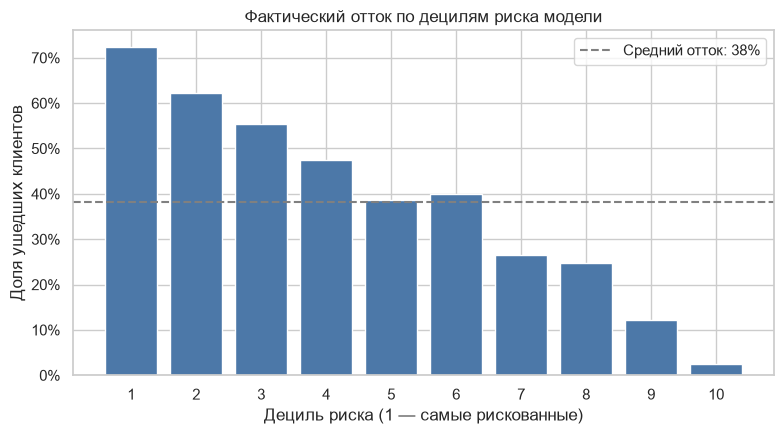

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(dec.index.astype(str), dec["churn_rate"], color="#4C78A8")
ax.axhline(base, color="gray", linestyle="--", label=f"Средний отток: {base:.0%}")
ax.set_xlabel("Дециль риска (1 — самые рискованные)")
ax.set_ylabel("Доля ушедших клиентов")
ax.set_title("Фактический отток по децилям риска модели")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/churn_deciles.png", dpi=150)
plt.show()

In [23]:
imp = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES_S).sort_values(ascending=False)
imp.round(3)


cutoff_month        0.641
avg_gap_days        0.355
frequency           0.338
revenue_last_90d    0.163
monetary            0.161
recency             0.114
orders_last_90d     0.104
tenure              0.079
avg_lines           0.057
avg_items           0.043
returns_cnt         0.043
avg_order_value     0.037
revenue_last_30d    0.016
is_uk               0.008
orders_last_30d     0.006
single_order        0.000
dtype: float64

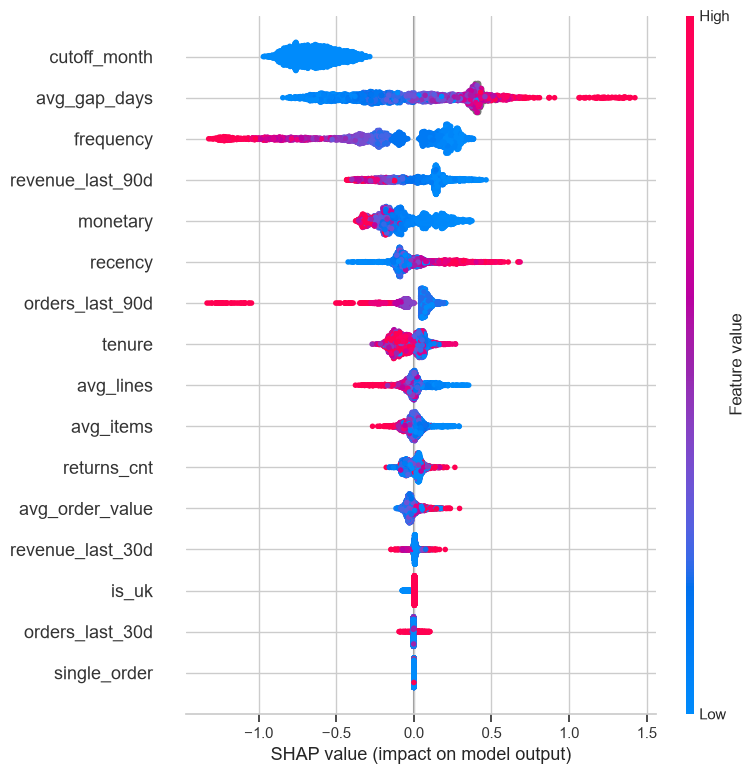

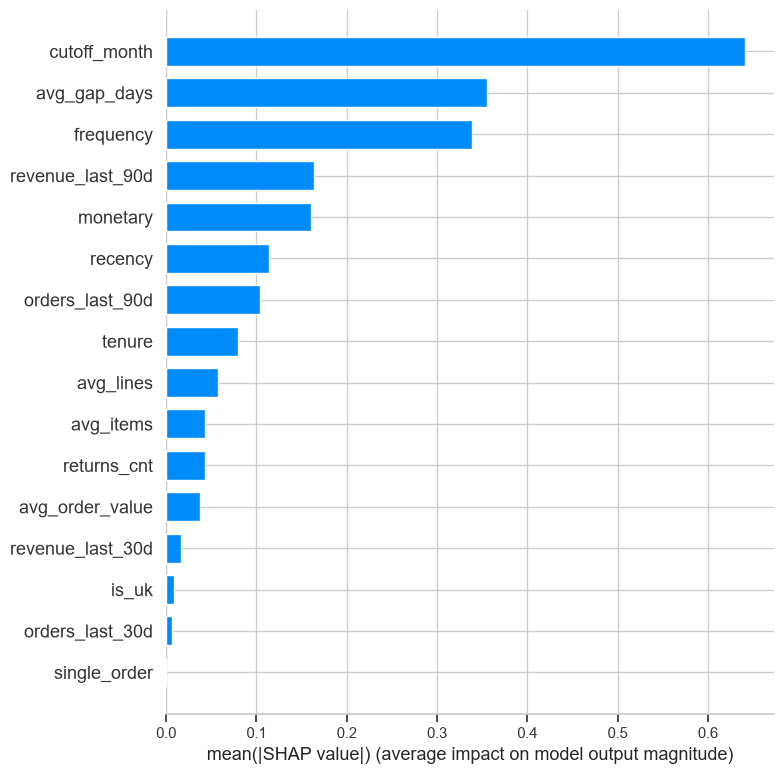

In [24]:
plt.figure(figsize=(9, 6))
shap.summary_plot(sv, X_shap, show=False)
plt.tight_layout()
plt.savefig("../reports/figures/shap_summary.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
shap.summary_plot(sv, X_shap, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("../reports/figures/shap_importance.png", dpi=150)
plt.show()

<Figure size 700x450 with 0 Axes>

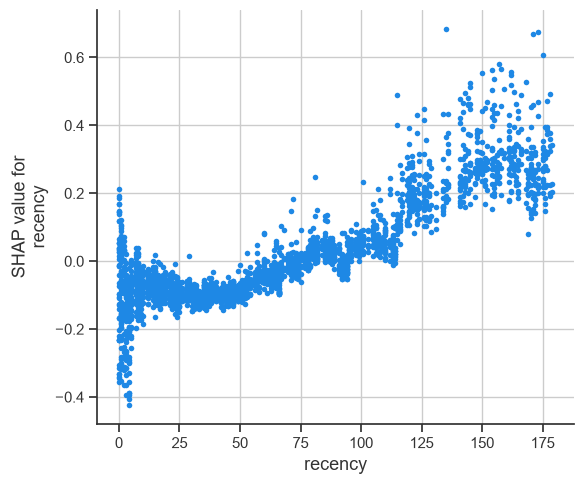

In [25]:
plt.figure(figsize=(7, 4.5))
shap.dependence_plot("recency", sv, X_shap, interaction_index=None, show=False)
plt.tight_layout()
plt.savefig("../reports/figures/shap_recency.png", dpi=150)
plt.show()

In [26]:
i = int(np.argmax(proba))
contrib = pd.Series(sv[i], index=FEATURES_S).sort_values(key=np.abs, ascending=False).head(6)
print("CustomerID:", X_shap.index[i], "| риск:", round(proba[i], 3))
print(pd.DataFrame({"значение": X_shap.iloc[i][contrib.index], "вклад SHAP": contrib.round(3)}))

CustomerID: 15256 | риск: 0.86
                  значение  вклад SHAP
avg_gap_days        413.00       1.275
cutoff_month          9.00      -0.577
frequency             2.00       0.272
monetary            170.40       0.242
avg_items            46.00       0.147
revenue_last_90d     98.45       0.122


avg_gap_days        0.355
frequency           0.338
revenue_last_90d    0.163
monetary            0.161
recency             0.114
orders_last_90d     0.104
tenure              0.079
avg_lines           0.057
avg_items           0.043
returns_cnt         0.043
avg_order_value     0.037
revenue_last_30d    0.016
is_uk               0.008
orders_last_30d     0.006
single_order        0.000
dtype: float64


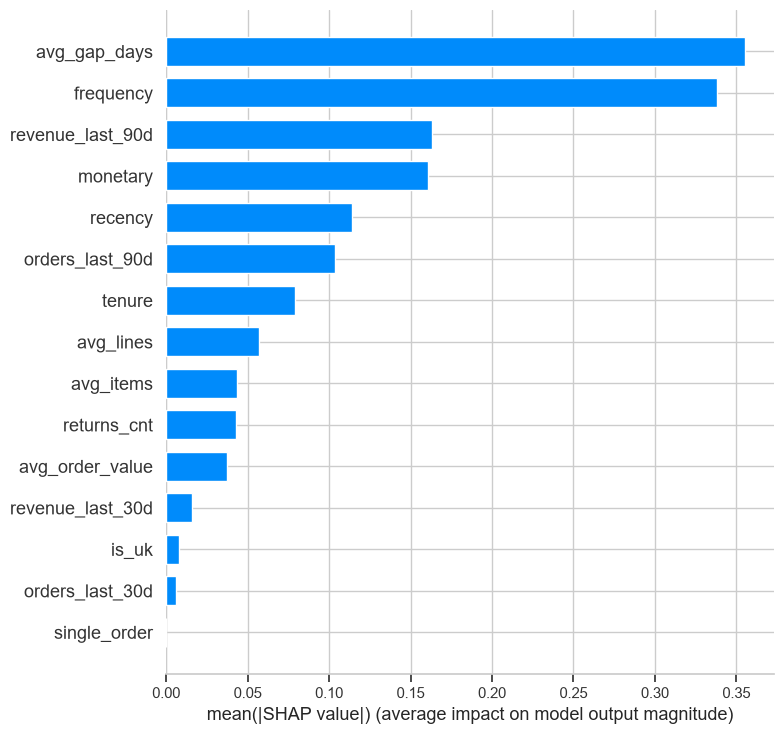

In [27]:
cols = list(X_shap.columns)
keep = [i for i, c in enumerate(cols) if c != "cutoff_month"]
imp2 = pd.Series(np.abs(sv[:, keep]).mean(axis=0), index=[cols[i] for i in keep]).sort_values(ascending=False)
print(imp2.round(3))

plt.figure(figsize=(8, 5))
shap.summary_plot(sv[:, keep], X_shap.iloc[:, keep], plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("../reports/figures/shap_importance_no_season.png", dpi=150)
plt.show()